In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# each point is length, width, type (0, 1)

#data = [[3,   1.5, 1],
        #[2,   1,   0],
        #[4,   1.5, 1],
        #[3,   1,   0],
        #[3.5, .5,  1],
        #[2,   .5,  0],
        #[5.5,  1,  1],
        #[1,    1,  0]]

#mystery_flower = [5, 1]

data = ['You are singing','Ram is there','Ram is not there','Ram is also there','Super is here','Super se upar']
   L = [0,1,2,3,4,5]
   V = ['You','are','singing','Ram','is','there','not','also','Super','here','se','upar']
   S1 = [111000000000]
   S2 = [000111000000]
   S3 = [000111100000]

   vector for new [1000]

h = xE - lookup function
h(s1) = [111000000000] 1st layer
S= h*w
h is a matrix



#mystery_flower = [5, 1]

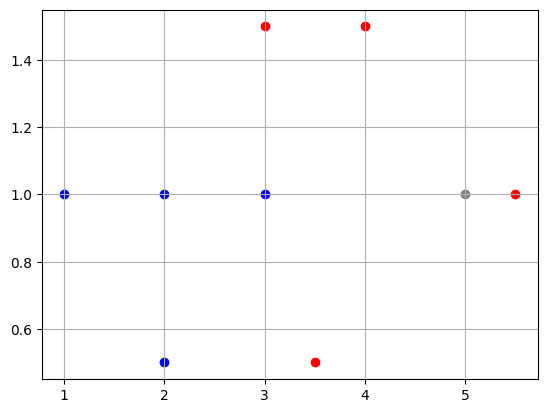

In [ ]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [ ]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [ ]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

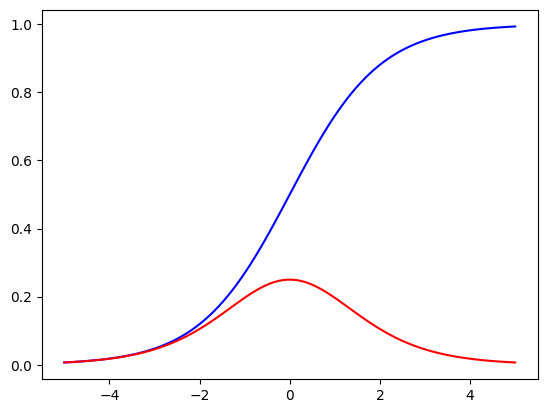

In [ ]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

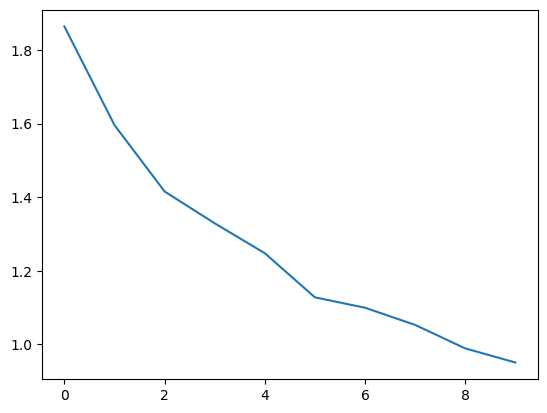

In [ ]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 1000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [ ]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9953645774858603
close to 0 -> blue, close to 1 -> red


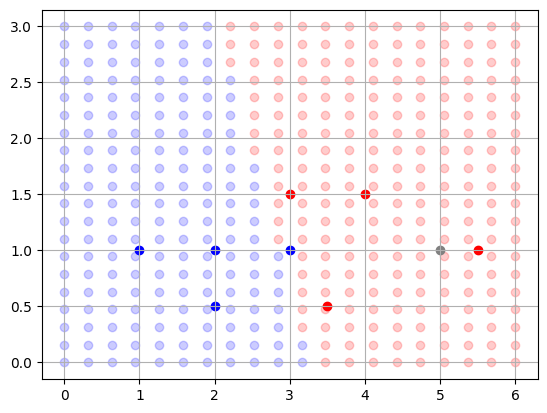

In [ ]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

In [1]:
import numpy as np

def softmax(x):
    """Compute softmax values for each sets of scores in x."""
    e_x = np.exp(x - np.max(x)) # Numerical stability
    return e_x / e_x.sum(axis=0, keepdims=True)

def word2vec_skipgram(corpus, c, d, eta, T):
    """
    Word2Vec Skip-Gram implementation based on the provided exercise pseudo-code.

    Parameters:
    - corpus: List of sentences (each sentence is a list of string tokens)
    - c: Context window size
    - d: Embedding dimension (size of vector)
    - eta: Learning rate (eta)
    - T: Number of epochs

    Returns:
    - E: Input embeddings matrix
    """

    # 1. Build vocabulary V from the corpus
    vocab = list(set(word for sentence in corpus for word in sentence))
    vocab_size = len(vocab)
    word_to_idx = {word: i for i, word in enumerate(vocab)}
    idx_to_word = {i: word for i, word in enumerate(vocab)}

    # 2. Initialize input embeddings E randomly (shape: |V| x d)
    # Using small random values centered around 0
    E = np.random.randn(vocab_size, d) * 0.01

    # 3. Initialize output weights W randomly (shape: d x |V|)
    W = np.random.randn(d, vocab_size) * 0.01

    # 4. Generate training pairs
    training_pairs = []
    for sentence in corpus:
        sentence_len = len(sentence)
        for i in range(sentence_len):
            w = sentence[i]
            w_idx = word_to_idx[w]

            # Define context window boundaries
            start = max(0, i - c)
            end = min(sentence_len, i + c + 1)

            for j in range(start, end):
                if i != j:
                    context_word = sentence[j]
                    context_idx = word_to_idx[context_word]
                    training_pairs.append((w_idx, context_idx))

    # 5. For epoch = 1 to T:
    for epoch in range(T):
        # Shuffle training pairs
        np.random.shuffle(training_pairs)

        total_loss = 0.0
        for center, context in training_pairs:
            # --- Forward pass ---
            # h = E[center] (shape: (d,))
            h = E[center]

            # scores = h x W (shape: (|V|,))
            scores = np.dot(h, W)

            # probabilities = Softmax(scores)
            probabilities = softmax(scores)

            # --- Compute loss ---
            loss = -np.log(probabilities[context] + 1e-15)
            total_loss += loss

            # --- Backpropagation ---
            error = probabilities.copy()
            error[context] -= 1  # error[context] -= 1

            # gradient_W = h^T x error (outer product or matrix multiplication)
            # h is (d,), error is (|V|,), so outer product gives (d x |V|)
            gradient_W = np.outer(h, error)

            # gradient_h = W x error (shape: (d,))
            gradient_h = np.dot(W, error)

            # --- Update parameters ---
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h

        print(f"Epoch {epoch + 1}/{T} completed. Loss: {total_loss:.4f}")

    # 6. Return E
    return E

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    # Sample corpus tokenized into sentences
    sample_corpus = [
        ["the", "quick", "brown", "fox", "jumps"],
        ["over", "the", "lazy", "dog"]
    ]

    # Hyperparameters: window size c=2, embedding dim d=10, learning rate=0.01, epochs=5
    embeddings = word2vec_skipgram(sample_corpus, c=2, d=10, eta=0.01, T=5)
    print("\nFinal Input Embeddings Shape:", embeddings.shape)

Epoch 1/5 completed. Loss: 49.9076
Epoch 2/5 completed. Loss: 49.9074
Epoch 3/5 completed. Loss: 49.9072
Epoch 4/5 completed. Loss: 49.9069
Epoch 5/5 completed. Loss: 49.9067

Final Input Embeddings Shape: (8, 10)


In [2]:
import numpy as np

def softmax(x):
    """Compute softmax values for each sets of scores in x."""
    e_x = np.exp(x - np.max(x)) # Numerical stability
    return e_x / e_x.sum(axis=0, keepdims=True)

def word2vec_skipgram(corpus, c, d, eta, T):
    """
    Word2Vec Skip-Gram implementation with explicit Tokenization and Weight Matrix display.
    """

    print("=" * 50)
    print("1. TOKENIZATION & VOCABULARY BUILDING")
    print("=" * 50)

    # Explicit Tokenization: Flattening and unique token extraction
    tokens = [word for sentence in corpus for word in sentence]
    vocab = sorted(list(set(tokens)))
    vocab_size = len(vocab)

    word_to_idx = {word: i for i, word in enumerate(vocab)}
    idx_to_word = {i: word for i, word in enumerate(vocab)}

    print(f"Original Corpus Sentences: {len(corpus)}")
    print(f"Total Tokens: {len(tokens)}")
    print(f"Vocabulary Size (|V|): {vocab_size}")
    print(f"Vocabulary List: {vocab}")
    print(f"Word-to-Index Mapping: {word_to_idx}")
    print(f"Index-to-Word Mapping: {idx_to_word}\n")

    print("=" * 50)
    print("2 & 3. WEIGHT MATRICES INITIALIZATION")
    print("=" * 50)

    # 2. Initialize input embeddings E randomly (shape: |V| x d)
    E = np.random.randn(vocab_size, d) * 0.01

    # 3. Initialize output weights W randomly (shape: d x |V|)
    W = np.random.randn(d, vocab_size) * 0.01

    print(f"Input Embeddings Matrix (E) Shape: {E.shape}  -> (|V| x d)")
    print(f"Output Weights Matrix (W) Shape: {W.shape}     -> (d x |V|)")
    print("\nInitial Input Embeddings (E) sample (first 3 words):")
    for i in range(min(3, vocab_size)):
        print(f"  {idx_to_word[i]} (idx {i}): {np.round(E[i], 4)}")

    print("\nInitial Output Weights (W) sample (first 3 columns):")
    print(np.round(W[:, :3], 4))
    print("\n" + "=" * 50)
    print("4 & 5. TRAINING PHASE")
    print("=" * 50)

    # 4. Generate training pairs
    training_pairs = []
    for sentence in corpus:
        sentence_len = len(sentence)
        for i in range(sentence_len):
            w = sentence[i]
            w_idx = word_to_idx[w]

            start = max(0, i - c)
            end = min(sentence_len, i + c + 1)

            for j in range(start, end):
                if i != j:
                    context_word = sentence[j]
                    context_idx = word_to_idx[context_word]
                    training_pairs.append((w_idx, context_idx))

    print(f"Generated {len(training_pairs)} training pairs (center, context).\n")

    # 5. Epoch loop
    for epoch in range(T):
        np.random.shuffle(training_pairs)
        total_loss = 0.0

        for center, context in training_pairs:
            # Forward pass
            h = E[center]
            scores = np.dot(h, W)
            probabilities = softmax(scores)

            # Compute loss
            loss = -np.log(probabilities[context] + 1e-15)
            total_loss += loss

            # Backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = np.dot(W, error)

            # Update parameters
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h

        print(f"Epoch {epoch + 1}/{T} completed | Total Loss: {total_loss:.4f}")

    print("\n" + "=" * 50)
    print("6. FINAL WEIGHT MATRICES (AFTER TRAINING)")
    print("=" * 50)
    print(f"Final Input Embeddings (E):\n{np.round(E, 4)}")
    print(f"\nFinal Output Weights (W):\n{np.round(W, 4)}")

    return E, W

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    sample_corpus = [
        ["the", "quick", "brown", "fox", "jumps"],
        ["over", "the", "lazy", "dog"]
    ]

    # Run algorithm with window size c=2, embedding dim d=4, learning rate=0.01, epochs=5
    E_final, W_final = word2vec_skipgram(sample_corpus, c=2, d=4, eta=0.01, T=5)

1. TOKENIZATION & VOCABULARY BUILDING
Original Corpus Sentences: 2
Total Tokens: 9
Vocabulary Size (|V|): 8
Vocabulary List: ['brown', 'dog', 'fox', 'jumps', 'lazy', 'over', 'quick', 'the']
Word-to-Index Mapping: {'brown': 0, 'dog': 1, 'fox': 2, 'jumps': 3, 'lazy': 4, 'over': 5, 'quick': 6, 'the': 7}
Index-to-Word Mapping: {0: 'brown', 1: 'dog', 2: 'fox', 3: 'jumps', 4: 'lazy', 5: 'over', 6: 'quick', 7: 'the'}

2 & 3. WEIGHT MATRICES INITIALIZATION
Input Embeddings Matrix (E) Shape: (8, 4)  -> (|V| x d)
Output Weights Matrix (W) Shape: (4, 8)     -> (d x |V|)

Initial Input Embeddings (E) sample (first 3 words):
  brown (idx 0): [-0.0128  0.0066  0.0091  0.0097]
  dog (idx 1): [-0.0271 -0.0142 -0.0111  0.0013]
  fox (idx 2): [-0.0049  0.0014  0.0046  0.0103]

Initial Output Weights (W) sample (first 3 columns):
[[ 0.0029  0.007  -0.004 ]
 [-0.0037  0.0091 -0.0015]
 [-0.0043 -0.018   0.0016]
 [ 0.0134  0.0053  0.0091]]

4 & 5. TRAINING PHASE
Generated 24 training pairs (center, context)

In [3]:
import numpy as np

def softmax(x):
    """Compute softmax values for each set of scores in x."""
    e_x = np.exp(x - np.max(x)) # Numerical stability
    return e_x / e_x.sum(axis=0, keepdims=True)

def word2vec_skipgram(corpus, c, d, eta, T):
    """
    Word2Vec Skip-Gram implementation with Tokenization, Weight Matrices,
    and Training Pair Generation visualization[cite: 2].
    """

    print("=" * 60)
    print("1. TOKENIZATION & VOCABULARY BUILDING")
    print("=" * 60)

    tokens = [word for sentence in corpus for word in sentence]
    vocab = sorted(list(set(tokens)))
    vocab_size = len(vocab)

    word_to_idx = {word: i for i, word in enumerate(vocab)}
    idx_to_word = {i: word for i, word in enumerate(vocab)}

    print(f"Vocabulary Size (|V|): {vocab_size}")
    print(f"Vocabulary List: {vocab}")
    print(f"Word-to-Index Mapping: {word_to_idx}\n")

    print("=" * 60)
    print("2 & 3. WEIGHT MATRICES INITIALIZATION")
    print("=" * 60)

    E = np.random.randn(vocab_size, d) * 0.01  # Input embeddings (|V| x d)
    W = np.random.randn(d, vocab_size) * 0.01  # Output weights (d x |V|)

    print(f"Input Embeddings (E) Matrix Shape: {E.shape}")
    print(f"Output Weights (W) Matrix Shape: {W.shape}\n")

    print("=" * 60)
    print("4. GENERATE TRAINING PAIRS (Visualization)")
    print("=" * 60)
    print(f"Using Context Window Size (c) = {c}\n")

    training_pairs = []

    # Pseudocode implementation:
    # For each sentence in Corpus[cite: 2]:
    for s_idx, sentence in enumerate(corpus):
        print(f"--- Sentence {s_idx + 1}: {sentence} ---")
        sentence_len = len(sentence)

        # For each word w at position i[cite: 2]:
        for i in range(sentence_len):
            w = sentence[i]
            w_idx = word_to_idx[w]

            # For each context position j within window c:
            start = max(0, i - c)
            end = min(sentence_len, i + c + 1)

            context_window_words = []
            for j in range(start, end):
                # If i != j:
                if i != j:
                    context_word = sentence[j]
                    context_idx = word_to_idx[context_word]
                    training_pairs.append((w_idx, context_idx))
                    context_window_words.append(context_word)

            print(f"  Position i={i} | Center Word: '{w}' (idx {w_idx}) | Context Window Words: {context_window_words}")

    print(f"\nTotal Training Pairs Generated: {len(training_pairs)}")
    print(f"Training Pairs (Word-level):")
    for p in training_pairs:
        print(f"  ('{idx_to_word[p[0]]}', '{idx_to_word[p[1]]}') -> Indices: {p}")
    print("\n" + "=" * 60)
    print("5 & 6. TRAINING PHASE & FINAL MATRICES")
    print("=" * 60)

    # 5. Epoch loop
    for epoch in range(T):
        np.random.shuffle(training_pairs)
        total_loss = 0.0

        for center, context in training_pairs:
            # Forward pass
            h = E[center]
            scores = np.dot(h, W)
            probabilities = softmax(scores)

            # Compute loss
            loss = -np.log(probabilities[context] + 1e-15)
            total_loss += loss

            # Backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = np.dot(W, error)

            # Update parameters
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h

        print(f"Epoch {epoch + 1}/{T} completed | Loss: {total_loss:.4f}")

    return E, W

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    sample_corpus = [
        ["the", "quick", "brown"],
        ["lazy", "dog"]
    ]

    # Run with context window c=1, embedding dim d=4, learning rate=0.01, epochs=2
    E_final, W_final = word2vec_skipgram(sample_corpus, c=1, d=4, eta=0.01, T=2)

1. TOKENIZATION & VOCABULARY BUILDING
Vocabulary Size (|V|): 5
Vocabulary List: ['brown', 'dog', 'lazy', 'quick', 'the']
Word-to-Index Mapping: {'brown': 0, 'dog': 1, 'lazy': 2, 'quick': 3, 'the': 4}

2 & 3. WEIGHT MATRICES INITIALIZATION
Input Embeddings (E) Matrix Shape: (5, 4)
Output Weights (W) Matrix Shape: (4, 5)

4. GENERATE TRAINING PAIRS (Visualization)
Using Context Window Size (c) = 1

--- Sentence 1: ['the', 'quick', 'brown'] ---
  Position i=0 | Center Word: 'the' (idx 4) | Context Window Words: ['quick']
  Position i=1 | Center Word: 'quick' (idx 3) | Context Window Words: ['the', 'brown']
  Position i=2 | Center Word: 'brown' (idx 0) | Context Window Words: ['quick']
--- Sentence 2: ['lazy', 'dog'] ---
  Position i=0 | Center Word: 'lazy' (idx 2) | Context Window Words: ['dog']
  Position i=1 | Center Word: 'dog' (idx 1) | Context Window Words: ['lazy']

Total Training Pairs Generated: 6
Training Pairs (Word-level):
  ('the', 'quick') -> Indices: (4, 3)
  ('quick', 'the'

In [4]:
import numpy as np

def softmax(x):
    """Compute softmax values for each set of scores in x."""
    e_x = np.exp(x - np.max(x)) # Numerical stability
    return e_x / e_x.sum(axis=0, keepdims=True)

def word2vec_skipgram_onehot(corpus, eta, T):
    """
    Word2Vec Skip-Gram implementation using One-Hot Encoding for input representations
    instead of random initialization.
    """

    print("=" * 60)
    print("1. TOKENIZATION & VOCABULARY BUILDING")
    print("=" * 60)

    tokens = [word for sentence in corpus for word in sentence]
    vocab = sorted(list(set(tokens)))
    vocab_size = len(vocab)

    word_to_idx = {word: i for i, word in enumerate(vocab)}
    idx_to_word = {i: word for i, word in enumerate(vocab)}

    print(f"Vocabulary Size (|V|): {vocab_size}")
    print(f"Vocabulary List: {vocab}")
    print(f"Word-to-Index Mapping: {word_to_idx}\n")

    print("=" * 60)
    print("2 & 3. ONE-HOT ENCODING & WEIGHT INITIALIZATION")
    print("=" * 60)

    # 2. Initialize input embeddings E using One-Hot Encoding (Identity Matrix of size |V| x |V|)
    # Each word's input representation is now a distinct one-hot vector.
    E = np.eye(vocab_size)

    # 3. Initialize output weights W randomly (shape: |V| x |V|)
    W = np.random.randn(vocab_size, vocab_size) * 0.01

    print(f"Input Embeddings (E) Matrix Shape (One-Hot Identity): {E.shape}")
    print(f"Output Weights (W) Matrix Shape: {W.shape}\n")

    print("Visualization of One-Hot Vectors (E rows):")
    for word, idx in word_to_idx.items():
        print(f"  '{word}' (idx {idx}): {E[idx]}")
    print()

    print("=" * 60)
    print("4. GENERATE TRAINING PAIRS (Visualization)")
    print("=" * 60)
    c = 1  # Context window size
    training_pairs = []

    for s_idx, sentence in enumerate(corpus):
        print(f"--- Sentence {s_idx + 1}: {sentence} ---")
        sentence_len = len(sentence)

        for i in range(sentence_len):
            w = sentence[i]
            w_idx = word_to_idx[w]

            start = max(0, i - c)
            end = min(sentence_len, i + c + 1)

            context_window_words = []
            for j in range(start, end):
                if i != j:
                    context_word = sentence[j]
                    context_idx = word_to_idx[context_word]
                    training_pairs.append((w_idx, context_idx))
                    context_window_words.append(context_word)

            print(f"  Position i={i} | Center Word: '{w}' (idx {w_idx}) | Context Window: {context_window_words}")

    print(f"\nTotal Training Pairs Generated: {len(training_pairs)}\n")

    print("=" * 60)
    print("5 & 6. TRAINING PHASE & FINAL MATRICES")
    print("=" * 60)

    for epoch in range(T):
        np.random.shuffle(training_pairs)
        total_loss = 0.0

        for center, context in training_pairs:
            # Forward pass using the one-hot input vector
            h = E[center]  # One-hot vector for the center word
            scores = np.dot(h, W)
            probabilities = softmax(scores)

            # Compute loss
            loss = -np.log(probabilities[context] + 1e-15)
            total_loss += loss

            # Backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = np.dot(W, error)

            # Update parameters
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h  # Updating one-hot rows directly

        print(f"Epoch {epoch + 1}/{T} completed | Loss: {total_loss:.4f}")

    return E, W

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    sample_corpus = [
        ["the", "quick", "brown"],
        ["lazy", "dog"]
    ]

    E_final, W_final = word2vec_skipgram_onehot(sample_corpus, eta=0.01, T=2)

1. TOKENIZATION & VOCABULARY BUILDING
Vocabulary Size (|V|): 5
Vocabulary List: ['brown', 'dog', 'lazy', 'quick', 'the']
Word-to-Index Mapping: {'brown': 0, 'dog': 1, 'lazy': 2, 'quick': 3, 'the': 4}

2 & 3. ONE-HOT ENCODING & WEIGHT INITIALIZATION
Input Embeddings (E) Matrix Shape (One-Hot Identity): (5, 5)
Output Weights (W) Matrix Shape: (5, 5)

Visualization of One-Hot Vectors (E rows):
  'brown' (idx 0): [1. 0. 0. 0. 0.]
  'dog' (idx 1): [0. 1. 0. 0. 0.]
  'lazy' (idx 2): [0. 0. 1. 0. 0.]
  'quick' (idx 3): [0. 0. 0. 1. 0.]
  'the' (idx 4): [0. 0. 0. 0. 1.]

4. GENERATE TRAINING PAIRS (Visualization)
--- Sentence 1: ['the', 'quick', 'brown'] ---
  Position i=0 | Center Word: 'the' (idx 4) | Context Window: ['quick']
  Position i=1 | Center Word: 'quick' (idx 3) | Context Window: ['the', 'brown']
  Position i=2 | Center Word: 'brown' (idx 0) | Context Window: ['quick']
--- Sentence 2: ['lazy', 'dog'] ---
  Position i=0 | Center Word: 'lazy' (idx 2) | Context Window: ['dog']
  Posit

In [5]:
import numpy as np

def softmax(x):
    """Compute softmax values for each set of scores in x."""
    e_x = np.exp(x - np.max(x)) # Numerical stability
    return e_x / e_x.sum(axis=0, keepdims=True)

def word2vec_skipgram_onehot(corpus, eta, T):
    """
    Word2Vec Skip-Gram implementation using One-Hot Encoding with final matrix display.
    """

    print("=" * 60)
    print("1. TOKENIZATION & VOCABULARY BUILDING")
    print("=" * 60)

    tokens = [word for sentence in corpus for word in sentence]
    vocab = sorted(list(set(tokens)))
    vocab_size = len(vocab)

    word_to_idx = {word: i for i, word in enumerate(vocab)}
    idx_to_word = {i: word for i, word in enumerate(vocab)}

    print(f"Vocabulary Size (|V|): {vocab_size}")
    print(f"Vocabulary List: {vocab}")
    print(f"Word-to-Index Mapping: {word_to_idx}\n")

    print("=" * 60)
    print("2 & 3. ONE-HOT ENCODING & WEIGHT INITIALIZATION")
    print("=" * 60)

    # Initialize input embeddings E using One-Hot Encoding (Identity Matrix)
    E = np.eye(vocab_size)

    # Initialize output weights W randomly
    W = np.random.randn(vocab_size, vocab_size) * 0.01

    print(f"Input Embeddings (E) Matrix Shape: {E.shape}")
    print(f"Output Weights (W) Matrix Shape: {W.shape}\n")

    print("Visualization of Initial One-Hot Vectors (E rows):")
    for word, idx in word_to_idx.items():
        print(f"  '{word}' (idx {idx}): {E[idx]}")
    print()

    print("=" * 60)
    print("4. GENERATE TRAINING PAIRS")
    print("=" * 60)
    c = 1  # Context window size
    training_pairs = []

    for s_idx, sentence in enumerate(corpus):
        print(f"--- Sentence {s_idx + 1}: {sentence} ---")
        sentence_len = len(sentence)

        for i in range(sentence_len):
            w = sentence[i]
            w_idx = word_to_idx[w]

            start = max(0, i - c)
            end = min(sentence_len, i + c + 1)

            context_window_words = []
            for j in range(start, end):
                if i != j:
                    context_word = sentence[j]
                    context_idx = word_to_idx[context_word]
                    training_pairs.append((w_idx, context_idx))
                    context_window_words.append(context_word)

            print(f"  Position i={i} | Center Word: '{w}' (idx {w_idx}) | Context Window: {context_window_words}")

    print(f"\nTotal Training Pairs Generated: {len(training_pairs)}\n")

    print("=" * 60)
    print("5. TRAINING PHASE")
    print("=" * 60)

    for epoch in range(T):
        np.random.shuffle(training_pairs)
        total_loss = 0.0

        for center, context in training_pairs:
            # Forward pass
            h = E[center]
            scores = np.dot(h, W)
            probabilities = softmax(scores)

            # Compute loss
            loss = -np.log(probabilities[context] + 1e-15)
            total_loss += loss

            # Backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = np.dot(W, error)

            # Update parameters
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h

        print(f"Epoch {epoch + 1}/{T} completed | Loss: {total_loss:.4f}")

    print("\n" + "=" * 60)
    print("6. FINAL WEIGHT MATRICES (AFTER TRAINING)")
    print("=" * 60)

    print("\nFinal Input Embeddings Matrix (E):\n", np.round(E, 4))
    print("\nFinal Output Weights Matrix (W):\n", np.round(W, 4))

    print("\nFinal Word Vectors (Rows of E mapped to words):")
    for word, idx in word_to_idx.items():
        print(f"  '{word}': {np.round(E[idx], 4)}")

    return E, W

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    sample_corpus = [
        ["the", "quick", "brown"],
        ["lazy", "dog"]
    ]

    E_final, W_final = word2vec_skipgram_onehot(sample_corpus, eta=0.01, T=2)

1. TOKENIZATION & VOCABULARY BUILDING
Vocabulary Size (|V|): 5
Vocabulary List: ['brown', 'dog', 'lazy', 'quick', 'the']
Word-to-Index Mapping: {'brown': 0, 'dog': 1, 'lazy': 2, 'quick': 3, 'the': 4}

2 & 3. ONE-HOT ENCODING & WEIGHT INITIALIZATION
Input Embeddings (E) Matrix Shape: (5, 5)
Output Weights (W) Matrix Shape: (5, 5)

Visualization of Initial One-Hot Vectors (E rows):
  'brown' (idx 0): [1. 0. 0. 0. 0.]
  'dog' (idx 1): [0. 1. 0. 0. 0.]
  'lazy' (idx 2): [0. 0. 1. 0. 0.]
  'quick' (idx 3): [0. 0. 0. 1. 0.]
  'the' (idx 4): [0. 0. 0. 0. 1.]

4. GENERATE TRAINING PAIRS
--- Sentence 1: ['the', 'quick', 'brown'] ---
  Position i=0 | Center Word: 'the' (idx 4) | Context Window: ['quick']
  Position i=1 | Center Word: 'quick' (idx 3) | Context Window: ['the', 'brown']
  Position i=2 | Center Word: 'brown' (idx 0) | Context Window: ['quick']
--- Sentence 2: ['lazy', 'dog'] ---
  Position i=0 | Center Word: 'lazy' (idx 2) | Context Window: ['dog']
  Position i=1 | Center Word: 'dog